# Анализ данных: бюджет, сборы и длительность фильмов

Лабораторная работа №4, часть «Анализ данных». Евграфов Р. А., ИДБ-25-11, вариант 7 (фильмы).

[![Открыть в Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/machtahhhhher-stack/lab4/blob/main/analysis/films_analysis.ipynb)

## 1. Постановка задачи

Тема бота — фильмы, поэтому и для анализа взяты данные о фильмах. Вопросы исследования:

1. Связаны ли **бюджет** фильма и его **кассовые сборы**? Окупаются ли дорогие фильмы лучше?
2. Как распределена **длительность** фильмов — можно ли считать распределение нормальным?
3. Связана ли **оценка критиков** (Metacritic) с коммерческим успехом фильма?

Инструменты: NumPy, Pandas, Matplotlib.

## 2. Поиск данных

Набор данных собран самостоятельно из открытой базы знаний **Викиданные** (Wikidata) SPARQL-запросом
(скрипт `data/collect_dataset.py` в репозитории). Взяты фильмы 1980–2024 годов, у которых указаны
и бюджет, и кассовые сборы **в долларах США**.

| Столбец | Что означает |
|---|---|
| `film` | ссылка на фильм в Викиданных |
| `title_ru`, `title_en` | название на русском и английском |
| `year` | год выхода |
| `budget_usd` | бюджет, $ |
| `box_office_usd` | кассовые сборы, $ |
| `duration_min` | длительность, минут |
| `country`, `genre` | одна из стран производства и один из жанров |
| `metacritic` | оценка критиков Metacritic в виде строки «73/100» |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

URL = "https://raw.githubusercontent.com/machtahhhhher-stack/lab4/main/data/films_raw.csv"
try:
    raw = pd.read_csv("../data/films_raw.csv")   # блокнот открыт из папки проекта
except FileNotFoundError:
    raw = pd.read_csv(URL)                       # Google Colab: берём файл прямо с GitHub
print(raw.shape)
raw.head()

(2755, 10)


,film,title_ru,title_en,year,budget_usd,box_office_usd,duration_min,country,genre,metacritic
0,http://www.wikidata.org/entity/Q1449248,Страх высоты,High Anxiety,1982,"3,400,000.00","31,063,038.00",94.00,США,кинопародия,55/100
1,http://www.wikidata.org/entity/Q392924,Аэропорт 1975,Airport 1975,1980,"3,000,000.00","103,000,000.00",107.00,США,фильм-триллер,50/100
2,http://www.wikidata.org/entity/Q403033,Побег из Нью-Йорка,NaN,1981,"6,000,000.00","25,274,965.00",99.00,США,антиутопический фильм,76/100
3,http://www.wikidata.org/entity/Q409064,Аэропорт-79: «Конкорд»,The Concorde ... Airport '79,1980,"14,000,000.00","65,000,000.00",106.00,США,фильм-катастрофа,39/100
4,http://www.wikidata.org/entity/Q426517,Правосудие для всех,...And Justice for All,1980,"4,000,000.00","33,300,000.00",119.00,США,процессуальная драма,58/100


In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2755 entries, 0 to 2754
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   film            2755 non-null   object 
 1   title_ru        2636 non-null   object 
 2   title_en        2147 non-null   object 
 3   year            2755 non-null   int64  
 4   budget_usd      2755 non-null   float64
 5   box_office_usd  2755 non-null   float64
 6   duration_min    2743 non-null   float64
 7   country         2755 non-null   object 
 8   genre           2755 non-null   object 
 9   metacritic      2266 non-null   object 
dtypes: float64(3), int64(1), object(6)
memory usage: 215.4+ KB


## 3. Подготовка данных

«Сырые» данные нужно очистить:

* **дубликаты** — фильм с несколькими датами выхода попадал в запрос несколько раз;
* **пропуски** — у части фильмов нет длительности или оценки;
* **типы** — оценка записана строкой «73/100», нужно число;
* **выбросы и ошибки** — в Викиданных встречаются опечатки (длительность 10 809 минут, бюджет 6 000 $).

In [3]:
print("Пропуски по столбцам:")
print(raw.isna().sum())
print("\nСтрок:", len(raw), " уникальных фильмов:", raw["film"].nunique())

Пропуски по столбцам:
film                0
title_ru          119
title_en          608
year                0
budget_usd          0
box_office_usd      0
duration_min       12
country             0
genre               0
metacritic        489
dtype: int64

Строк: 2755  уникальных фильмов: 2430


In [4]:
df = (raw.sort_values("year")
         .drop_duplicates("film", keep="first")       # оставляем самый ранний год выхода
         .copy())

# оценка "73/100" -> 73.0 (регулярное выражение достаёт число)
df["metacritic_score"] = df["metacritic"].str.extract(r"(\d+)/100", expand=False).astype(float)

# название: русское, а если его нет - английское
df["title"] = df["title_ru"].fillna(df["title_en"]).fillna("без названия")

print("После удаления дубликатов:", len(df))
df[["budget_usd", "box_office_usd", "duration_min", "metacritic_score"]].describe()

После удаления дубликатов: 2430


,budget_usd,box_office_usd,duration_min,metacritic_score
count,"2,430.00","2,430.00","2,420.00","1,998.00"
mean,"44,088,352.96","149,415,008.89",121.81,58.81
std,"54,494,105.05","248,659,357.30",282.61,17.41
min,"6,000.00",22.81,12.00,1.00
25%,"8,000,000.00","12,001,558.00",97.00,47.00
50%,"22,200,000.00","53,996,869.00",109.00,59.00
75%,"60,000,000.00","181,969,346.25",123.25,72.00
max,"410,000,000.00","2,847,379,794.00","10,809.00",100.00


In [5]:
# Явные ошибки: бюджет меньше 100 тысяч $ и сборы меньше 1000 $ для фильмов с полноценным
# прокатом неправдоподобны; длительность меньше 40 минут - уже короткометражка,
# больше 5 часов - ошибка ввода (минуты перепутаны с секундами и т.п.)
before = len(df)
df = df[(df["budget_usd"] >= 1e5) & (df["box_office_usd"] >= 1e3)]
df.loc[~df["duration_min"].between(40, 300), "duration_min"] = np.nan
print("Удалено строк с ошибочными деньгами:", before - len(df))
print("Длительностей признано ошибочными:", df["duration_min"].isna().sum())

Удалено строк с ошибочными деньгами: 23
Длительностей признано ошибочными: 12


In [6]:
# Новые признаки
df["roi"] = df["box_office_usd"] / df["budget_usd"]              # во сколько раз сборы больше бюджета
df["profitable"] = np.where(df["roi"] > 1, "окупился", "не окупился")
df["decade"] = (df["year"] // 10 * 10).astype(int).astype(str) + "-е"
df["log_budget"] = np.log10(df["budget_usd"])                     # деньги - на логарифмической шкале
df["log_box"] = np.log10(df["box_office_usd"])

clean = df[["title", "year", "decade", "country", "genre", "budget_usd", "box_office_usd",
            "roi", "profitable", "duration_min", "metacritic_score", "log_budget", "log_box"]]
print("Итоговый набор:", clean.shape)
clean.head()

Итоговый набор: (2407, 13)


,title,year,decade,country,genre,budget_usd,box_office_usd,roi,profitable,duration_min,metacritic_score,log_budget,log_box
1,Аэропорт 1975,1980,1980-е,США,фильм-триллер,"3,000,000.00","103,000,000.00",34.33,окупился,107.00,50.00,6.48,8.01
84,Псы войны,1980,1980-е,США,драматический фильм,"8,000,000.00","5,484,132.00",0.69,не окупился,104.00,56.00,6.90,6.74
95,Весь этот джаз,1980,1980-е,США,драматический фильм,"12,000,000.00","37,823,676.00",3.15,окупился,123.00,72.00,7.08,7.58
91,Флэш Гордон,1980,1980-е,США,боевик,"27,000,000.00","27,107,960.00",1.00,окупился,111.00,58.00,7.43,7.43
92,Чёрное воскресенье,1980,1980-е,США,фильм-катастрофа,"8,000,000.00","15,769,322.00",1.97,окупился,143.00,57.00,6.90,7.20


## 4. Исследование данных

In [7]:
clean[["budget_usd", "box_office_usd", "roi", "duration_min", "metacritic_score"]].describe(
    percentiles=[0.1, 0.5, 0.9])

,budget_usd,box_office_usd,roi,duration_min,metacritic_score
count,"2,407.00","2,407.00","2,407.00","2,395.00","1,987.00"
mean,"44,491,247.74","150,633,437.87",4.65,112.47,58.75
std,"54,593,394.85","249,456,225.26",12.85,21.08,17.41
min,"100,000.00","1,800.00",0.00,47.00,1.00
10%,"2,800,000.00","2,300,000.00",0.36,90.00,35.60
50%,"23,000,000.00","55,003,135.00",2.40,109.00,59.00
90%,"120,000,000.00","390,732,476.80",8.76,138.00,82.00
max,"410,000,000.00","2,847,379,794.00",426.78,263.00,100.00


In [8]:
print("Медианная окупаемость:", round(clean["roi"].median(), 2), "раза")
print(clean["profitable"].value_counts(normalize=True).round(3))
print("\nСамые окупаемые фильмы:")
clean.nlargest(5, "roi")[["title", "year", "budget_usd", "box_office_usd", "roi"]]

Медианная окупаемость: 2.4 раза
profitable
окупился      0.76
не окупился   0.24
Name: proportion, dtype: float64

Самые окупаемые фильмы:


,title,year,budget_usd,box_office_usd,roi
32,Братья Блюз,1980,"270,000.00","115,229,890.00",426.78
115,Алиса в Стране чудес,1982,"400,000.00","90,000,000.00",225.00
260,Супермегеры,1984,"100,000.00","17,000,000.00",170.00
1159,Космическая станция 3D,2002,"1,000,000.00","127,000,000.00",127.00
54,Выход дракона,1980,"850,000.00","90,000,000.00",105.88


In [9]:
by_decade = clean.groupby("decade").agg(
    фильмов=("title", "count"),
    медиана_бюджета=("budget_usd", "median"),
    медиана_сборов=("box_office_usd", "median"),
    медиана_окупаемости=("roi", "median"),
)
by_decade

,фильмов,медиана_бюджета,медиана_сборов,медиана_окупаемости
decade,,,,
1980-е,393,"9,000,000.00","21,192,102.00",2.67
1990-е,393,"30,000,000.00","60,527,873.00",2.21
2000-е,613,"27,000,000.00","66,200,000.00",2.20
2010-е,854,"30,000,000.00","77,926,572.50",2.59
2020-е,154,"50,000,000.00","91,899,811.00",2.14


In [10]:
top_genres = clean["genre"].value_counts().head(8)
genre_stats = (clean[clean["genre"].isin(top_genres.index)]
               .groupby("genre")["roi"].median().sort_values(ascending=False))
print(top_genres)
genre_stats

genre
фильм-триллер                  249
комедийный фильм               104
романтическая комедия           99
драматический фильм             89
антиутопический фильм           72
научно-фантастический фильм     66
криминальный фильм              62
супергеройский фильм            62
Name: count, dtype: int64


genre
романтическая комедия         3.29
супергеройский фильм          3.25
фильм-триллер                 2.21
научно-фантастический фильм   1.91
комедийный фильм              1.73
антиутопический фильм         1.66
криминальный фильм            1.52
драматический фильм           1.21
Name: roi, dtype: float64

In [11]:
corr = clean[["log_budget", "log_box", "roi", "duration_min", "metacritic_score", "year"]].corr()
corr.round(2)

,log_budget,log_box,roi,duration_min,metacritic_score,year
log_budget,1.00,0.75,-0.21,0.41,-0.18,0.24
log_box,0.75,1.00,0.15,0.35,0.01,0.14
roi,-0.21,0.15,1.00,-0.02,0.11,-0.10
duration_min,0.41,0.35,-0.02,1.00,0.31,0.12
metacritic_score,-0.18,0.01,0.11,0.31,1.00,0.03
year,0.24,0.14,-0.10,0.12,0.03,1.00


## 5. Визуализация

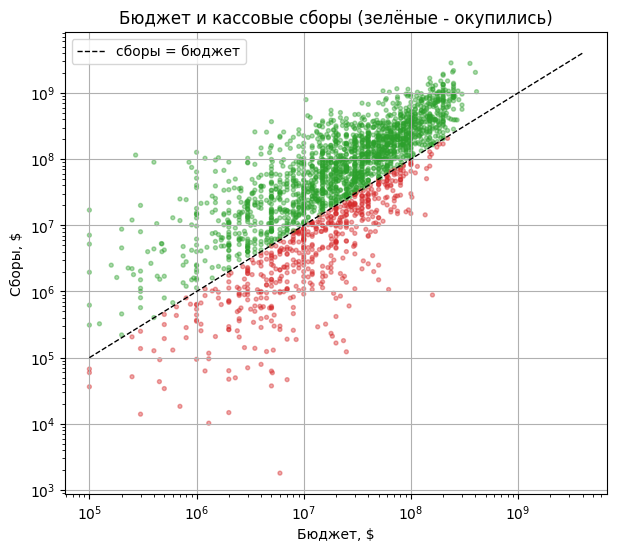

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = np.where(clean["roi"] > 1, "tab:green", "tab:red")
ax.scatter(clean["budget_usd"], clean["box_office_usd"], s=8, alpha=0.4, c=colors)
lim = [1e5, 4e9]
ax.plot(lim, lim, "k--", lw=1, label="сборы = бюджет")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Бюджет, $"); ax.set_ylabel("Сборы, $")
ax.set_title("Бюджет и кассовые сборы (зелёные - окупились)")
ax.legend()
plt.show()

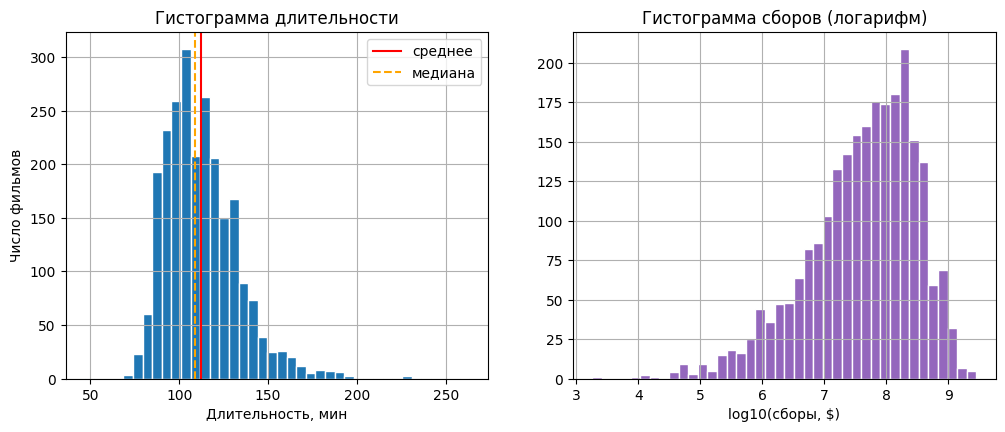

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.hist(clean["duration_min"].dropna(), bins=40, color="tab:blue", edgecolor="white")
ax1.axvline(clean["duration_min"].mean(), color="red", label="среднее")
ax1.axvline(clean["duration_min"].median(), color="orange", ls="--", label="медиана")
ax1.set_xlabel("Длительность, мин"); ax1.set_ylabel("Число фильмов")
ax1.set_title("Гистограмма длительности"); ax1.legend()
ax2.hist(clean["log_box"], bins=40, color="tab:purple", edgecolor="white")
ax2.set_xlabel("log10(сборы, $)"); ax2.set_title("Гистограмма сборов (логарифм)")
plt.show()

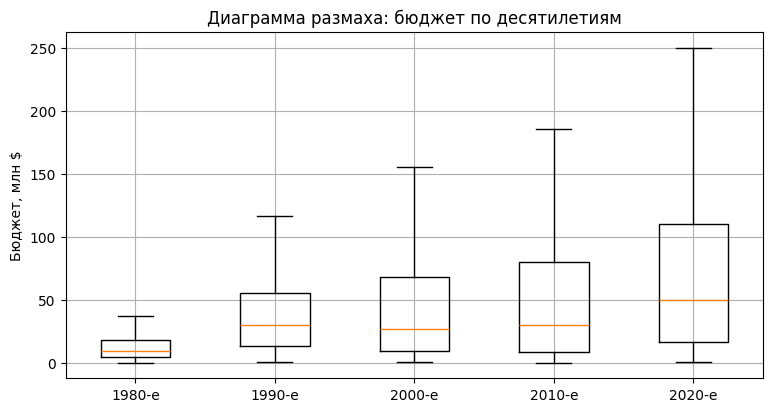

In [14]:
decades = sorted(clean["decade"].unique())
data = [clean.loc[clean["decade"] == d, "budget_usd"] / 1e6 for d in decades]
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(decades) + 1), decades)   # подписи - так работает в любой версии
plt.ylabel("Бюджет, млн $"); plt.title("Диаграмма размаха: бюджет по десятилетиям")
plt.show()

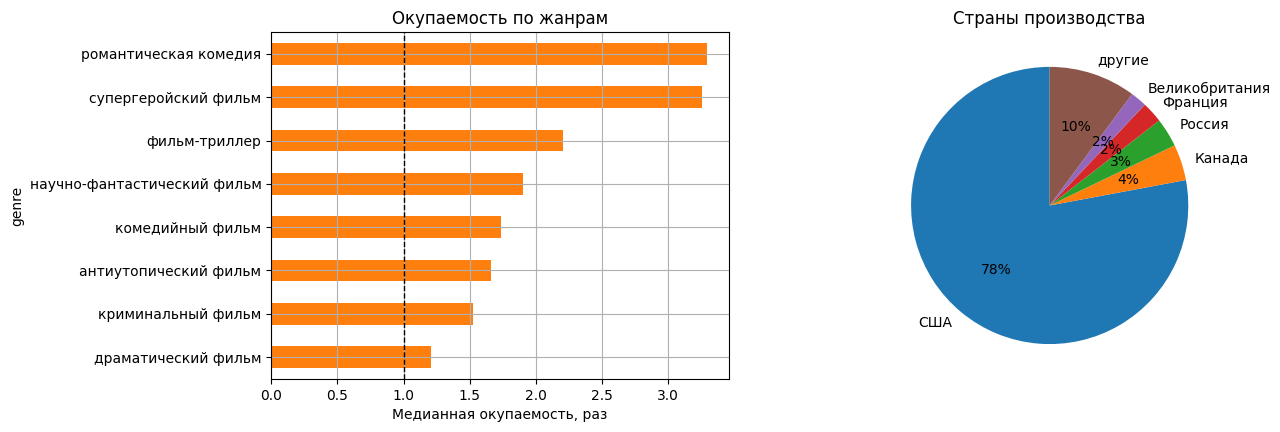

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
genre_stats.sort_values().plot.barh(ax=ax1, color="tab:orange")
ax1.axvline(1, color="k", ls="--", lw=1)
ax1.set_xlabel("Медианная окупаемость, раз"); ax1.set_title("Окупаемость по жанрам")
countries = clean["country"].value_counts()
share = pd.concat([countries.head(5), pd.Series({"другие": countries.iloc[5:].sum()})])
ax2.pie(share, labels=share.index, autopct="%1.0f%%", startangle=90)
ax2.set_title("Страны производства")
plt.show()

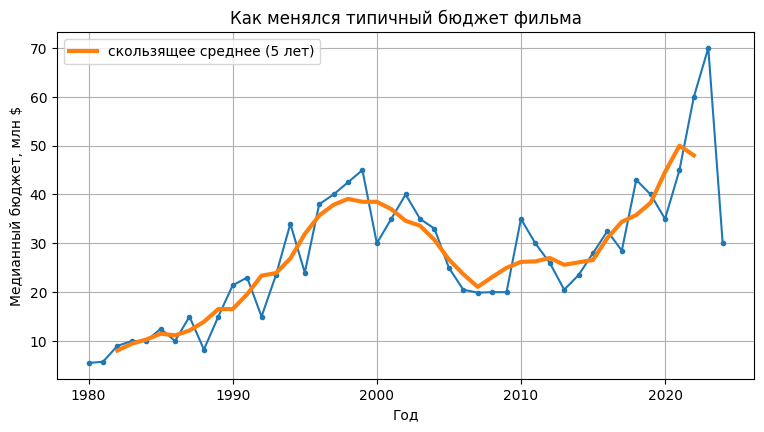

In [16]:
yearly = clean.groupby("year")["budget_usd"].median() / 1e6
plt.plot(yearly.index, yearly.values, marker="o", ms=3)
plt.plot(yearly.index, yearly.rolling(5, center=True).mean(), lw=3, label="скользящее среднее (5 лет)")
plt.xlabel("Год"); plt.ylabel("Медианный бюджет, млн $")
plt.title("Как менялся типичный бюджет фильма"); plt.legend()
plt.show()

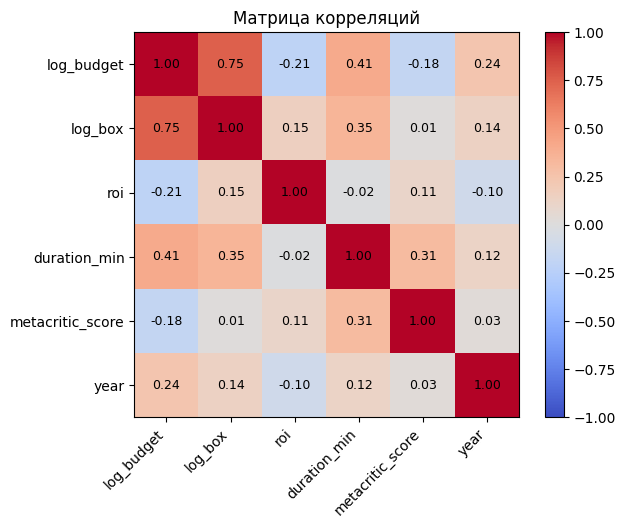

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im); ax.set_title("Матрица корреляций"); ax.grid(False)
plt.show()

## 6. Проверка статистических гипотез

### Гипотеза 1. Между бюджетом и сборами существует сильная положительная корреляция

Считаем коэффициенты корреляции **Пирсона** (линейная связь) и **Спирмена** (монотонная связь,
устойчива к выбросам; вычисляется как корреляция Пирсона между рангами значений).
По шкале Чеддока связь сильная при |r| ≥ 0,7.

In [18]:
pearson = clean["budget_usd"].corr(clean["box_office_usd"])
spearman = clean["budget_usd"].rank().corr(clean["box_office_usd"].rank())
pearson_log = clean["log_budget"].corr(clean["log_box"])

def strength(r):
    r = abs(r)
    return ("очень слабая" if r < 0.1 else "слабая" if r < 0.3 else "умеренная" if r < 0.5
            else "заметная" if r < 0.7 else "сильная")

print(f"Пирсон:              r = {pearson:.3f} ({strength(pearson)})")
print(f"Спирмен:             r = {spearman:.3f} ({strength(spearman)})")
print(f"Пирсон (логарифмы):  r = {pearson_log:.3f}")
print("Гипотеза 1", "ПОДТВЕРЖДАЕТСЯ" if min(pearson, spearman) >= 0.7 else "НЕ подтверждается")

Пирсон:              r = 0.753 (сильная)
Спирмен:             r = 0.777 (сильная)
Пирсон (логарифмы):  r = 0.746
Гипотеза 1 ПОДТВЕРЖДАЕТСЯ


### Гипотеза 2. Длительность фильмов распределена нормально

Для нормального распределения коэффициент асимметрии и эксцесс близки к нулю,
а по правилу трёх сигм в интервалы ±1σ, ±2σ, ±3σ попадает 68,3 %, 95,4 % и 99,7 % значений.

In [19]:
d = clean["duration_min"].dropna()
mean, std = d.mean(), d.std()
print(f"Среднее {mean:.1f} мин, медиана {d.median():.0f} мин, σ = {std:.1f}")
print(f"Асимметрия (skew): {d.skew():.2f}   эксцесс (kurt): {d.kurt():.2f}")

rule = pd.DataFrame({
    "интервал": ["±1σ", "±2σ", "±3σ"],
    "норма, %": [68.3, 95.4, 99.7],
    "факт, %": [((d - mean).abs() <= k * std).mean() * 100 for k in (1, 2, 3)],
})
print(rule.round(1).to_string(index=False))
normal = abs(d.skew()) < 0.5 and abs(d.kurt()) < 1
print("Гипотеза 2", "ПОДТВЕРЖДАЕТСЯ" if normal else "ОТВЕРГАЕТСЯ")

Среднее 112.5 мин, медиана 109 мин, σ = 21.1
Асимметрия (skew): 1.32   эксцесс (kurt): 3.80
интервал  норма, %  факт, %
     ±1σ     68.30    72.90
     ±2σ     95.40    95.90
     ±3σ     99.70    98.50
Гипотеза 2 ОТВЕРГАЕТСЯ


### Гипотеза 3. Высокие оценки критиков связаны с лучшей окупаемостью

In [20]:
m = clean.dropna(subset=["metacritic_score"])
r_roi = m["metacritic_score"].rank().corr(m["roi"].rank())
r_box = m["metacritic_score"].corr(m["log_box"])
print(f"Фильмов с оценкой Metacritic: {len(m)}")
print(f"Оценка и окупаемость (Спирмен): r = {r_roi:.3f} ({strength(r_roi)})")
print(f"Оценка и сборы (Пирсон, логарифм): r = {r_box:.3f} ({strength(r_box)})")

m = m.assign(группа=pd.cut(m["metacritic_score"], [0, 40, 60, 80, 100],
                           labels=["0-40", "41-60", "61-80", "81-100"]))
m.groupby("группа", observed=True)["roi"].agg(["count", "median"])

Фильмов с оценкой Metacritic: 1987
Оценка и окупаемость (Спирмен): r = 0.237 (слабая)
Оценка и сборы (Пирсон, логарифм): r = 0.011 (очень слабая)


,count,median
группа,,
0-40,307,2.00
41-60,742,2.54
61-80,700,3.20
81-100,238,4.19


## 7. Выводы

* Собран и очищен уникальный набор данных о ~2400 фильмах из Викиданных: удалены дубликаты,
  ошибочные значения, оценки приведены к числу, добавлены признаки окупаемости и десятилетия.
* **Гипотеза 1 подтверждается:** бюджет и сборы связаны сильной положительной корреляцией
  (Пирсон ≈ 0,75, Спирмен ≈ 0,78). Дорогие фильмы в среднем собирают больше, но не всегда окупаются лучше.
* **Гипотеза 2 отвергается:** распределение длительности имеет правостороннюю асимметрию (skew ≈ 1,3)
  и «тяжёлые хвосты» (эксцесс ≈ 3,8) — типичный фильм идёт около 1 ч 50 мин, но длинных фильмов
  заметно больше, чем было бы при нормальном распределении.
* **Гипотеза 3 подтверждается частично:** оценка критиков слабо положительно связана с окупаемостью
  (r ≈ 0,24), но почти не связана с абсолютными сборами — хорошие фильмы не обязательно кассовые.
* Около 76 % фильмов выборки окупились в прокате, медианная окупаемость — примерно 2,4 раза.